# Comparação das estratégias A, B e C

Este notebook reúne os históricos de validação das três estratégias e verifica se as rodadas utilizaram a mesma configuração e divisão dos dados.

A comparação busca responder quanto o pré-treinamento no COCO contribui para o DeepPCB e se o backbone precisa ser adaptado ao novo domínio.

## 1. Hipóteses

- **H1 — C × A:** o pré-treinamento no COCO deve melhorar o desempenho sob o orçamento fixo de treinamento.
- **H2 — C × B:** adaptar o backbone deve ser vantajoso devido à diferença entre fotografias naturais e imagens industriais.

A métrica principal é `map_50_95` de validação. `map_50`, precisão, recall e F1 são métricas secundárias. Como foi realizada uma execução por estratégia, os resultados não permitem estimar variação entre sementes.

In [3]:
from pathlib import Path

CONFIG = {
    # Caminho usado no Google Colab depois de montar o Drive.
    'drive_project_dir': '/content/drive/MyDrive/vision-transfer-learning',
    'results_dir': 'runs/results',
    'output_dir': 'runs/results/comparison',

    # Informe o nome da pasta da rodada, um caminho relativo a results_dir ou um caminho absoluto.
    # None seleciona automaticamente somente quando existe uma única candidata para a estratégia.
    'run_dirs': {
        'A': '20261124_050253_132291_A',
        'B': '20261123_195151_863513_B-isa',
        'C': '20261108_093008_344655_C'
    },
    'auto_select_latest_if_multiple': False,

    'primary_metric': 'map_50_95',
}

STRATEGIES = {
    'A': {'initialization': 'Aleatória', 'backbone': 'Treinável'},
    'B': {'initialization': 'COCO', 'backbone': 'Congelado'},
    'C': {'initialization': 'COCO', 'backbone': 'Treinável'},
}
COLORS = {'A': '#4C78A8', 'B': '#F58518', 'C': '#54A24B'}

## 2. Ambiente e resultados

No Colab, os resultados são carregados do Google Drive. Localmente, a raiz é identificada a partir do diretório atual.

In [4]:
import hashlib
import json
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

try:
    from google.colab import drive
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True
    drive.mount('/content/drive')

if IN_COLAB:
    PROJECT_DIR = Path(CONFIG['drive_project_dir']).expanduser().resolve()
else:
    candidates = [Path.cwd(), *Path.cwd().parents]
    PROJECT_DIR = next((path for path in candidates if (path / 'pyproject.toml').is_file()), None)
    if PROJECT_DIR is None:
        raise FileNotFoundError('Raiz do projeto não encontrada. Execute a partir de vision-transfer-learning.')

RESULTS_DIR = (PROJECT_DIR / CONFIG['results_dir']).resolve()
OUTPUT_DIR = (PROJECT_DIR / CONFIG['output_dir']).resolve()

if not RESULTS_DIR.is_dir():
    raise FileNotFoundError(f'Diretório de resultados não encontrado: {RESULTS_DIR}')

print('Ambiente:', 'Google Colab' if IN_COLAB else 'local')
print('Projeto:', PROJECT_DIR)
print('Resultados:', RESULTS_DIR)

Mounted at /content/drive
Ambiente: Google Colab
Projeto: /content/drive/.shortcut-targets-by-id/1mdTe8Ez5r7KCi5ryaBf_onUCZJHOlPqH/vision-transfer-learning
Resultados: /content/drive/.shortcut-targets-by-id/1mdTe8Ez5r7KCi5ryaBf_onUCZJHOlPqH/vision-transfer-learning/runs/results


## 3. Seleção das rodadas

As rodadas A, B e C são identificadas pelo `config.json`. Quando existe mais de uma execução da mesma estratégia, o diretório deve ser informado em `CONFIG['run_dirs']`.

In [5]:
def load_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))


def run_candidates(strategy):
    candidates = []
    for directory in RESULTS_DIR.glob(f'*_{strategy}'):
        config_path = directory / 'config.json'
        if directory.is_dir() and config_path.is_file():
            try:
                if load_json(config_path).get('experiment') == strategy:
                    candidates.append(directory.resolve())
            except (OSError, json.JSONDecodeError):
                continue
    return sorted(candidates, key=lambda path: path.stat().st_mtime)


candidate_rows = []
for strategy in STRATEGIES:
    for candidate in run_candidates(strategy):
        candidate_rows.append({
            'estratégia': strategy,
            'pasta': candidate.name,
            'modificado_em': datetime.fromtimestamp(candidate.stat().st_mtime).isoformat(timespec='seconds'),
        })

candidates_df = pd.DataFrame(candidate_rows)
if candidates_df.empty:
    print('Nenhuma rodada A/B/C encontrada automaticamente.')
else:
    display(candidates_df.sort_values(['estratégia', 'modificado_em']))

,estratégia,pasta,modificado_em
0,A,20261123_195825_142710_A,2026-11-23T19:58:25
1,A,20261123_215349_868496_A,2026-11-23T21:53:49
2,A,20261124_050253_132291_A,2026-11-24T05:02:53
3,B,20261123_224222_035876_B,2026-11-23T22:42:22
4,C,20261108_093008_344655_C,2026-11-08T13:54:30


In [6]:
def resolve_configured_run(value):
    path = Path(value).expanduser()
    if path.is_absolute():
        return path.resolve()
    direct = (RESULTS_DIR / path).resolve()
    return direct if direct.exists() else (PROJECT_DIR / path).resolve()


def select_run(strategy):
    configured = CONFIG['run_dirs'].get(strategy)
    if configured:
        selected = resolve_configured_run(configured)
        if not selected.is_dir():
            raise FileNotFoundError(f'Rodada {strategy} não encontrada: {selected}')
        return selected

    candidates = run_candidates(strategy)
    if not candidates:
        raise FileNotFoundError(f'Nenhuma rodada válida encontrada para a estratégia {strategy}.')
    if len(candidates) == 1:
        return candidates[0]
    if CONFIG['auto_select_latest_if_multiple']:
        print(f'Aviso: usando a rodada mais recente de {strategy}: {candidates[-1].name}')
        return candidates[-1]

    names = '\n  - '.join(str(path) for path in candidates)
    raise ValueError(
        f'Existem várias rodadas para {strategy}. Informe CONFIG["run_dirs"]["{strategy}"].'
        f'\n  - {names}'
    )


RUN_DIRS = {strategy: select_run(strategy) for strategy in STRATEGIES}
display(pd.DataFrame([{'estratégia': key, 'pasta selecionada': str(value)}
                      for key, value in RUN_DIRS.items()]))

,estratégia,pasta selecionada
0,A,/content/drive/.shortcut-targets-by-id/1mdTe8E...
1,B,/content/drive/.shortcut-targets-by-id/1mdTe8E...
2,C,/content/drive/.shortcut-targets-by-id/1mdTe8E...


## 4. Verificação das rodadas

Antes da comparação, são verificadas a configuração, a divisão dos dados e as colunas dos históricos. As únicas diferenças permitidas são a estratégia e o caminho do checkpoint.

In [7]:
REQUIRED_HISTORY_COLUMNS = {
    'epoch', 'train_loss', 'precision', 'recall', 'f1',
    'map_50', 'map_50_95', 'tp', 'fp', 'fn',
}
REQUIRED_SPLIT_COLUMNS = {'image_id', 'group_id', 'split'}
ALLOWED_CONFIG_DIFFERENCES = {'experiment', 'checkpoint_path'}


def load_run(strategy, directory):
    paths = {
        'config': directory / 'config.json',
        'split': directory / 'split.csv',
        'history': directory / 'history.csv',
    }
    missing_files = [str(path) for path in paths.values() if not path.is_file()]
    if missing_files:
        raise FileNotFoundError(f'Arquivos ausentes na rodada {strategy}: {missing_files}')

    config = load_json(paths['config'])
    split = pd.read_csv(paths['split'], dtype={'image_id': str, 'group_id': str, 'split': str})
    history = pd.read_csv(paths['history'])

    if config.get('experiment') != strategy:
        raise ValueError(f'A pasta indicada como {strategy} declara experiment={config.get("experiment")!r}.')
    missing_history = REQUIRED_HISTORY_COLUMNS - set(history.columns)
    missing_split = REQUIRED_SPLIT_COLUMNS - set(split.columns)
    if missing_history:
        raise ValueError(f'Histórico {strategy} sem colunas: {sorted(missing_history)}')
    if missing_split:
        raise ValueError(f'Divisão {strategy} sem colunas: {sorted(missing_split)}')
    if history.empty or history['epoch'].duplicated().any():
        raise ValueError(f'Histórico {strategy} vazio ou com épocas duplicadas.')

    metric = pd.to_numeric(history[CONFIG['primary_metric']], errors='coerce')
    if metric.isna().any() or not np.isfinite(metric).all():
        raise ValueError(f'Métrica principal inválida no histórico {strategy}.')

    return {'directory': directory, 'paths': paths, 'config': config, 'split': split, 'history': history}


RUNS = {strategy: load_run(strategy, directory) for strategy, directory in RUN_DIRS.items()}

In [8]:
def normalized_config(config):
    return {key: value for key, value in config.items() if key not in ALLOWED_CONFIG_DIFFERENCES}


reference_config = normalized_config(RUNS['A']['config'])
config_differences = []
for strategy in ('B', 'C'):
    current = normalized_config(RUNS[strategy]['config'])
    keys = sorted(set(reference_config) | set(current))
    for key in keys:
        if reference_config.get(key) != current.get(key):
            config_differences.append({
                'parâmetro': key, 'A': reference_config.get(key), strategy: current.get(key)
            })

if config_differences:
    display(pd.DataFrame(config_differences))
    raise ValueError('As configurações não são comparáveis. Corrija ou execute novamente as rodadas.')

split_columns = ['image_id', 'group_id', 'split']
reference_split = RUNS['A']['split'][split_columns].sort_values(split_columns).reset_index(drop=True)
for strategy in ('B', 'C'):
    current_split = RUNS[strategy]['split'][split_columns].sort_values(split_columns).reset_index(drop=True)
    if not reference_split.equals(current_split):
        merged = reference_split.merge(current_split, how='outer', indicator=True)
        display(merged[merged['_merge'] != 'both'].head(20))
        raise ValueError(f'A divisão da estratégia {strategy} difere da estratégia A.')

split_summary = reference_split.groupby('split').agg(
    imagens=('image_id', 'nunique'), grupos=('group_id', 'nunique')
).reset_index()
display(split_summary)
print('Configurações compatíveis: OK')
print('Divisões idênticas: OK')

,split,imagens,grupos
0,test,500,11
1,train,850,5
2,validation,150,2


Configurações compatíveis: OK
Divisões idênticas: OK


## 5. Tabela comparativa

A melhor época de cada estratégia é escolhida exclusivamente pelo maior `map_50_95` de validação. Em caso de empate numérico, fica a primeira época que atingiu o valor.

In [9]:
summary_rows = []
for strategy, run in RUNS.items():
    history = run['history'].sort_values('epoch').reset_index(drop=True)
    best = history.loc[history[CONFIG['primary_metric']].idxmax()]
    summary_rows.append({
        'strategy': strategy,
        'initialization': STRATEGIES[strategy]['initialization'],
        'backbone': STRATEGIES[strategy]['backbone'],
        'best_epoch': int(best['epoch']),
        'epochs_run': int(history['epoch'].max()),
        'map_50_95': float(best['map_50_95']),
        'map_50': float(best['map_50']),
        'precision': float(best['precision']),
        'recall': float(best['recall']),
        'f1': float(best['f1']),
        'train_loss': float(best['train_loss']),
        'run_dir': str(run['directory']),
    })

SUMMARY = pd.DataFrame(summary_rows).sort_values('strategy').reset_index(drop=True)
summary_view = SUMMARY.drop(columns=['run_dir']).copy()
numeric_columns = ['map_50_95', 'map_50', 'precision', 'recall', 'f1', 'train_loss']
summary_view[numeric_columns] = summary_view[numeric_columns].round(4)
summary_view['selected_by_validation'] = (
    summary_view['map_50_95'] == summary_view['map_50_95'].max()
)
display(summary_view.set_index('strategy'))

,initialization,backbone,best_epoch,epochs_run,map_50_95,map_50,precision,recall,f1,train_loss,selected_by_validation
strategy,,,,,,,,,,,
A,Aleatória,Treinável,12,17,0.6061,0.8667,0.5654,0.8674,0.6846,0.4069,False
B,COCO,Congelado,19,20,0.7214,0.9113,0.5807,0.9455,0.7195,0.2417,False
C,COCO,Treinável,15,20,0.7849,0.9540,0.7959,0.9566,0.8689,0.1157,True


In [10]:
metric_by_strategy = SUMMARY.set_index('strategy')[CONFIG['primary_metric']]
DELTA_ROWS = [
    {
        'comparison': 'C - A',
        'interpretation': 'valor observado do pré-treinamento com fine-tuning',
        'delta': float(metric_by_strategy['C'] - metric_by_strategy['A']),
    },
    {
        'comparison': 'C - B',
        'interpretation': 'valor observado de adaptar o backbone',
        'delta': float(metric_by_strategy['C'] - metric_by_strategy['B']),
    },
    {
        'comparison': 'B - A',
        'interpretation': 'comparação prática; inicialização e parâmetros treináveis mudam juntos',
        'delta': float(metric_by_strategy['B'] - metric_by_strategy['A']),
    },
]
DELTAS = pd.DataFrame(DELTA_ROWS)
DELTAS['percentage_points'] = DELTAS['delta'] * 100
delta_view = DELTAS.copy()
delta_view['delta'] = delta_view['delta'].round(4)
delta_view['percentage_points'] = delta_view['percentage_points'].round(2)
display(delta_view)

,comparison,interpretation,delta,percentage_points
0,C - A,valor observado do pré-treinamento com fine-tu...,0.1788,17.88
1,C - B,valor observado de adaptar o backbone,0.0635,6.35
2,B - A,comparação prática; inicialização e parâmetros...,0.1153,11.53


## 6. Curvas e gráficos

A mAP de validação é o gráfico principal. A perda descreve a otimização, mas não substitui a validação como critério de generalização. Não são exibidas barras de erro porque existe apenas uma execução por estratégia.

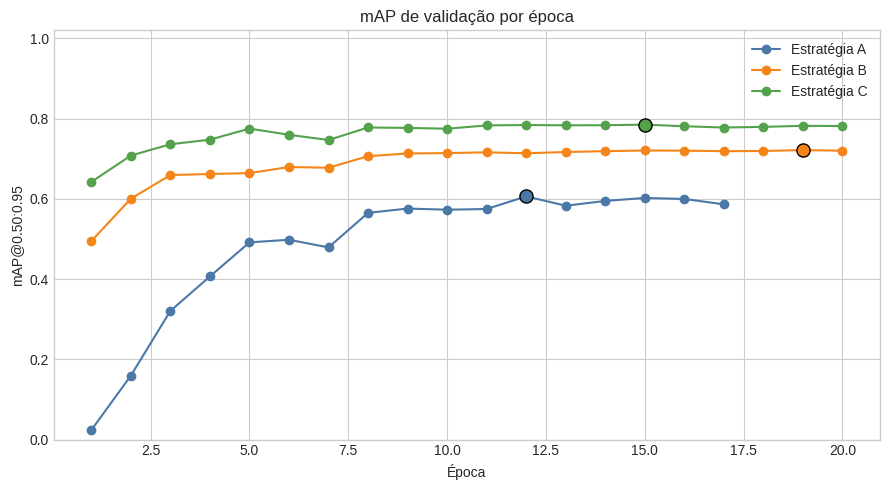

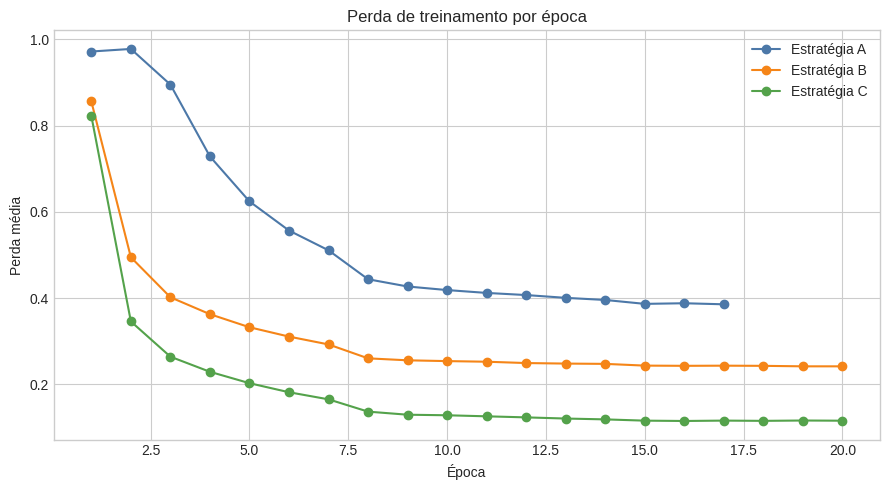

In [11]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')

fig, ax = plt.subplots(figsize=(9, 5))
for strategy, run in RUNS.items():
    history = run['history'].sort_values('epoch')
    ax.plot(history['epoch'], history[CONFIG['primary_metric']], marker='o',
            color=COLORS[strategy], label=f'Estratégia {strategy}')
    best = history.loc[history[CONFIG['primary_metric']].idxmax()]
    ax.scatter(best['epoch'], best[CONFIG['primary_metric']], s=90,
               color=COLORS[strategy], edgecolor='black', zorder=3)
ax.set(title='mAP de validação por época', xlabel='Época', ylabel='mAP@0.50:0.95', ylim=(0, 1.02))
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'validation_map_50_95.png', dpi=180, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
for strategy, run in RUNS.items():
    history = run['history'].sort_values('epoch')
    ax.plot(history['epoch'], history['train_loss'], marker='o',
            color=COLORS[strategy], label=f'Estratégia {strategy}')
ax.set(title='Perda de treinamento por época', xlabel='Época', ylabel='Perda média')
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'training_loss.png', dpi=180, bbox_inches='tight')
plt.show()

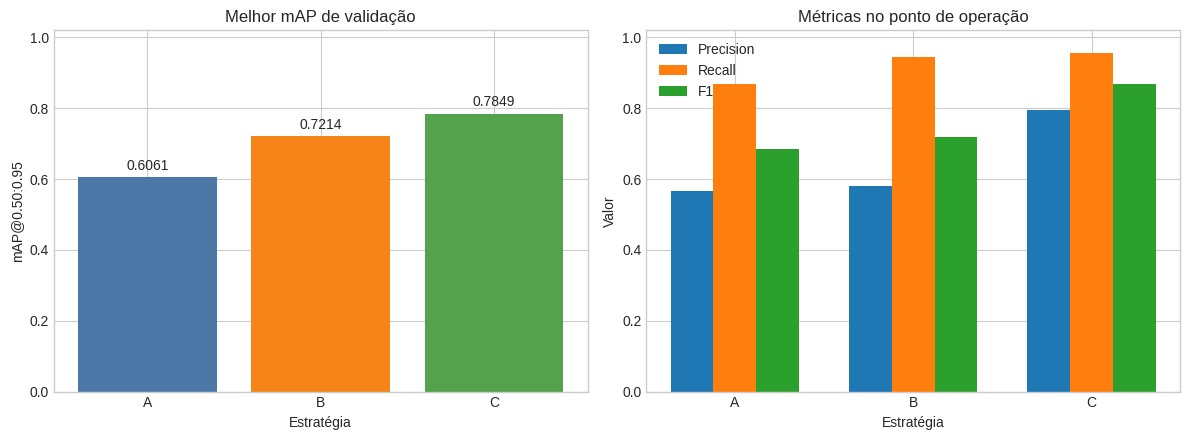

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
strategies = SUMMARY['strategy'].tolist()
colors = [COLORS[strategy] for strategy in strategies]

bars = axes[0].bar(strategies, SUMMARY['map_50_95'], color=colors)
axes[0].bar_label(bars, labels=[f'{value:.4f}' for value in SUMMARY['map_50_95']], padding=3)
axes[0].set(title='Melhor mAP de validação', xlabel='Estratégia', ylabel='mAP@0.50:0.95', ylim=(0, 1.02))

metrics = ['precision', 'recall', 'f1']
x = np.arange(len(strategies))
width = 0.24
for index, metric in enumerate(metrics):
    axes[1].bar(x + (index - 1) * width, SUMMARY[metric], width, label=metric.capitalize())
axes[1].set(title='Métricas no ponto de operação', xlabel='Estratégia', ylabel='Valor',
            xticks=x, xticklabels=strategies, ylim=(0, 1.02))
axes[1].legend()

fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'best_validation_comparison.png', dpi=180, bbox_inches='tight')
plt.show()

## 7. Seleção da estratégia

A célula seguinte identifica a maior mAP observada. Ela não declara significância estatística nem executa o teste. A interpretação deve considerar as curvas, a magnitude das diferenças e as limitações do protocolo.

In [13]:
winner = SUMMARY.sort_values([CONFIG['primary_metric'], 'strategy'], ascending=[False, True]).iloc[0]
delta_ca = float(DELTAS.loc[DELTAS['comparison'] == 'C - A', 'delta'].iloc[0])
delta_cb = float(DELTAS.loc[DELTAS['comparison'] == 'C - B', 'delta'].iloc[0])

report = f'''
### Resultado observado

- A estratégia **{winner['strategy']}** apresentou a maior mAP@0.50:0.95 de validação: **{winner['map_50_95']:.4f}**, na época **{int(winner['best_epoch'])}**.
- A diferença observada entre C e A foi de **{delta_ca:+.4f}** ({100 * delta_ca:+.2f} pontos percentuais).
- A diferença observada entre C e B foi de **{delta_cb:+.4f}** ({100 * delta_cb:+.2f} pontos percentuais).

A estratégia indicada para a avaliação final é **{winner['strategy']}**, pois a seleção foi definida previamente pela maior mAP@0.50:0.95 de validação. Como há apenas uma execução por estratégia, as diferenças não demonstram significância estatística. O teste deve ser avaliado separadamente, uma única vez, depois desta escolha.
'''
display(Markdown(report))
SELECTED_STRATEGY = str(winner['strategy'])


### Resultado observado

- A estratégia **C** apresentou a maior mAP@0.50:0.95 de validação: **0.7849**, na época **15**.
- A diferença observada entre C e A foi de **+0.1788** (+17.88 pontos percentuais).
- A diferença observada entre C e B foi de **+0.0635** (+6.35 pontos percentuais).

A estratégia indicada para a avaliação final é **C**, pois a seleção foi definida previamente pela maior mAP@0.50:0.95 de validação. Como há apenas uma execução por estratégia, as diferenças não demonstram significância estatística. O teste deve ser avaliado separadamente, uma única vez, depois desta escolha.


## 8. Exportação

A tabela comparativa, os deltas, as figuras e o manifesto das rodadas são salvos em `runs/results/comparison`.

In [14]:
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


SUMMARY.to_csv(OUTPUT_DIR / 'comparison.csv', index=False)
DELTAS.to_csv(OUTPUT_DIR / 'comparison_deltas.csv', index=False)

manifest = {
    'generated_at_utc': datetime.now(timezone.utc).isoformat(),
    'primary_metric': CONFIG['primary_metric'],
    'selected_strategy_by_validation': SELECTED_STRATEGY,
    'runs': {
        strategy: {
            'directory': str(run['directory']),
            'files': {name: {'path': str(path), 'sha256': sha256_file(path)}
                      for name, path in run['paths'].items()},
        }
        for strategy, run in RUNS.items()
    },
}
(OUTPUT_DIR / 'comparison_manifest.json').write_text(
    json.dumps(manifest, indent=2, ensure_ascii=False), encoding='utf-8'
)

print('Resultados exportados para:', OUTPUT_DIR)
for path in sorted(OUTPUT_DIR.iterdir()):
    print('-', path.name)

Resultados exportados para: /content/drive/.shortcut-targets-by-id/1mdTe8Ez5r7KCi5ryaBf_onUCZJHOlPqH/vision-transfer-learning/runs/results/comparison
- best_validation_comparison.png
- comparison.csv
- comparison_deltas.csv
- comparison_manifest.json
- training_loss.png
- validation_map_50_95.png


## 9. Avaliação final

A estratégia C foi selecionada pela validação. Sua avaliação no conjunto oficial de teste foi realizada separadamente no notebook `deep_pcb_transfer_learning_final_c.ipynb`.